In [2]:
import h5py
from tqdm import tqdm
import glob
import numpy as np
import os
from matplotlib import pyplot as plt

In [3]:
def read_files(glob_pattern, minyear=0, maxyear=9999):
    files = glob.glob(glob_pattern)
    resids = []

    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        hdf = h5py.File(fpath)
        resid = hdf['resid'][:]
        hdf.close()

        resids.append(resid)
        
    return np.array(resids)

In [4]:
resids = read_files('../data/validation/harmonic_samples/*.hdf5')

100%|██████████████████████████████████████████████████████████████████████████████| 2748/2748 [00:10<00:00, 251.90it/s]


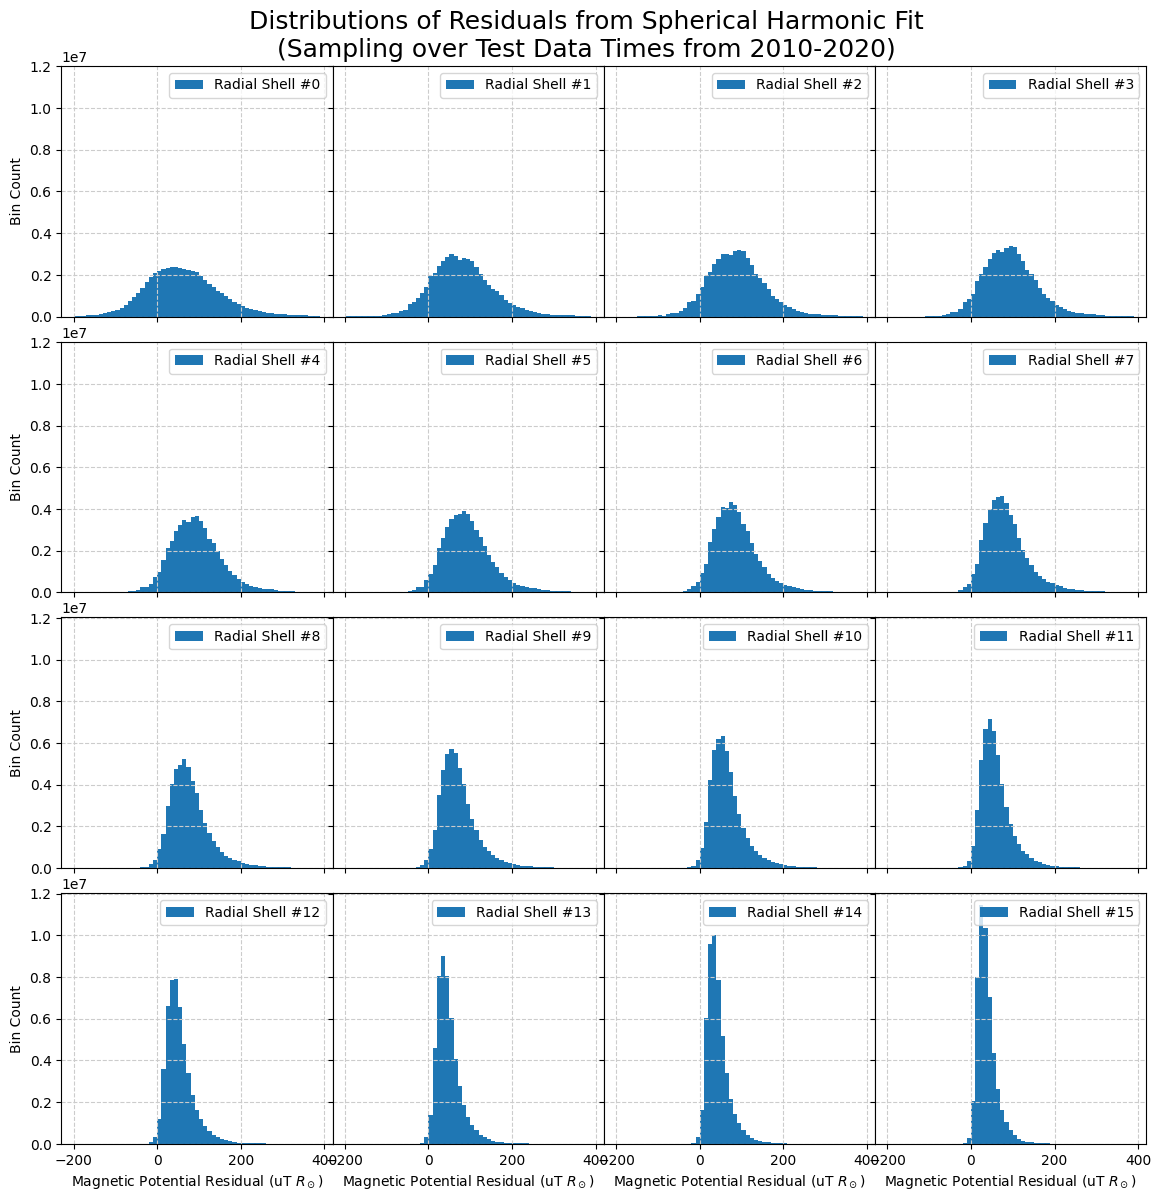

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(14,14), sharex='all', sharey='all')
bins = np.arange(-200, 400, 10)

for i, ax in enumerate(axes.flatten()):
    ax.hist(resids[:, i].flatten(), bins=bins, label=f'Radial Shell #{i}')
    ax.legend()
    ax.grid(linestyle='dashed', color='#ccc')
    
for ax in axes[-1, :]: 
    ax.set_xlabel(r'Magnetic Potential Residual (uT $R_\odot$)')
for ax in axes[:, 0]: 
    ax.set_ylabel('Bin Count')
    
plt.subplots_adjust(wspace=0, hspace=.1)
fig.suptitle('Distributions of Residuals from Spherical Harmonic Fit\n(Sampling over Test Data Times from 2010-2020)',
             y=0.92, fontsize=18)  
fig.savefig('../plots/paper/residuals.png')